Đây là mạng tự xây dựng cho Đồ án cuối kì môn Python cho Khoa Học Dữ Liệu.<br>
Dataset: Food-101. Link: https://www.kaggle.com/datasets/hari31416/food-101.<br>
Architecture: VGG16 model C (Có thay đổi so với mạng gốc). Link: https://arxiv.org/pdf/1409.1556.<br>
Hạn chế của file code này:<br>
- Độ phức tạp thuật toán cao.<br>
- Chưa thể hiệu chỉnh siêu tham số phù hợp cho riêng dataset này.<br>
- Chưa xử lý các ảnh trùng, sai nhãn.<br>
- Chưa huấn luyện mô hình chính thức mà chỉ chạy thử.

In [62]:
import time # Thư viện đo thời gian
import matplotlib.pyplot as plt # Thư viện biểu diễn hình ảnh
import numpy as np # Thư viện tính (không cần dùng)
import os # Thư viện đường dẫn
import random # Thư viện random
import torch # Thư viện tính toán cho DL
import hashlib # Thư viện tạo mã hash
from collections import defaultdict # Dict lưu các file có cùng mã hash
from PIL import Image # Đọc ảnh
from torchvision import transforms # Resize và crop ảnh

# Tiền xử lý dữ liệu<br>
Đọc 1 ảnh từ file.

(384, 512)


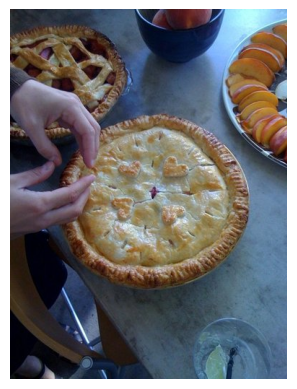

In [63]:
image_path = "/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/apple_pie/134.jpg"

image = Image.open(image_path)

print(image.size)

plt.imshow(image)
plt.axis("off")
plt.show()

Thu ảnh về 256.

<PIL.Image.Image image mode=RGB size=256x341 at 0x3184DCD10>


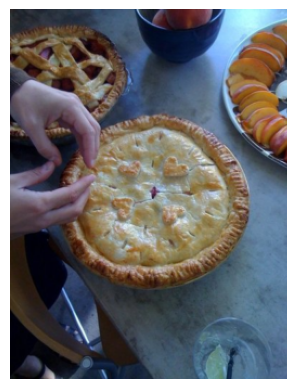

In [64]:
resize = transforms.Resize(256)
resized_image = resize(image)

print(resized_image)

plt.imshow(resized_image)
plt.axis("off")
plt.show()

Crop ảnh về 224 x 224. Có thể dùng RandomCrop hoặc CenterCrop.

<PIL.Image.Image image mode=RGB size=224x224 at 0x3184DD190>


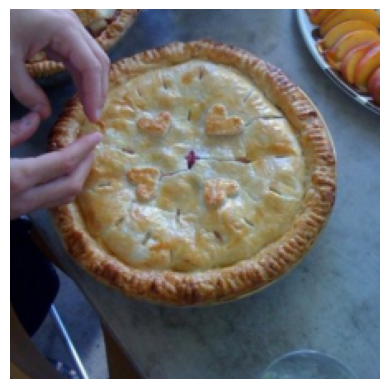

In [65]:
crop = transforms.RandomCrop(224)
cropped_image = crop(resized_image)

print(cropped_image)

plt.imshow(cropped_image)
plt.axis("off")
plt.show()

In [66]:
to_tensor = transforms.ToTensor()
image_tensor = to_tensor(cropped_image)
print(image_tensor.shape)


torch.Size([3, 224, 224])


Normalize cho 1 ảnh. Dùng công thức x' = (x - mean)/standard daviation (độ lệch chuẩn). 

In [67]:
# for i in range(0,3):
#     mean = 0
#     N = 224*224
#     std = 0
#     for j in range(0, 224):
#         for k in range(0,224):
#             mean += (image_tensor[i][j][k]/N)
#     for j in range(0, 224):
#         for k in range(0,224):
#             std += (image_tensor[i][j][k]-mean)**2
#     std /= N
#     std = np.sqrt(std)
#     for j in range(0, 224):
#         for k in range(0,224):
#             image_tensor[i][j][k] = (image_tensor[i][j][k]-mean)/std

# print(image_tensor.max())
# print(image_tensor.shape)

Đọc toàn bộ ảnh trong file.<br>
Hàm os.listdir(đường dẫn) trả về list chứa tên của tất cả file trong thư mục. 

In [ ]:
path = "/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train"

for class_name in os.listdir(path):
    print(class_name)
    if class_name != ".DS_Store":
        new_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}"
        for image in os.listdir(new_path):
            print(image)

Check ảnh trùng.<br>
Sử dụng Hash để đẩy ảnh vào và tìm các ảnh trùng nhau.<br>
Hàm defaultdict(list) tạo defaultdict. Defaultdict sẽ tự tạo key rỗng lúc thêm value còn dict thì sẽ phải tạo key trước rồi mới append value được. <br>
Hàm open(file, "rb") dùng để mở file và đọc ở dạng nhị phân (rb = read binary).<br>
Hàm file.read() để đọc nội dung file (vì đã gán giá trị cho biến file trước đó rồi).<br>
Hàm sha256 của thư viện hashlib sẽ chuyển nội dung file về dạng mã hash (sử dụng thuật toán cryptographic hash function để tạo ra mã hash 256 bit).<br>
Hàm hexdigest() sẽ chuyển chuỗi thành chuỗi thập lục phân (cho dễ lưu).<br>
Hàm items() trả về các cặp key, value của dict.<br>
Dòng duplicates tạo ra 1 cái dict được định nghĩa mới gồm key : value là những key mà có 2 value đổ lên trong deafaultdict hash_to_files.

In [69]:
hash_to_files = defaultdict(list)

for class_name in os.listdir(path):
    if class_name != ".DS_Store":
        new_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}"
        for image in os.listdir(new_path):
            image_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}/{image}"
            with open(image_path, "rb") as file:
                    file_hash = hashlib.sha256(file.read()).hexdigest()
                    hash_to_files[file_hash].append((class_name, image))

duplicates = {
    file_hash: files
    for file_hash, files in hash_to_files.items()
    if len(files) > 1
}

print("Số nhóm ảnh trùng:", len(duplicates))
for files in duplicates.values():
    print("\nNhóm ảnh trùng:")
    for class_name, image in files:
        print(f"Class: {class_name}, Image: {image}")

Số nhóm ảnh trùng: 7

Nhóm ảnh trùng:
Class: steak, Image: 97656.jpg
Class: prime_rib, Image: 76271.jpg

Nhóm ảnh trùng:
Class: churros, Image: 2547960.jpg
Class: churros, Image: 2617186.jpg

Nhóm ảnh trùng:
Class: paella, Image: 2199941.jpg
Class: paella, Image: 2199939.jpg

Nhóm ảnh trùng:
Class: hamburger, Image: 3578279.jpg
Class: hamburger, Image: 3783650.jpg

Nhóm ảnh trùng:
Class: dumplings, Image: 180290.jpg
Class: dumplings, Image: 167000.jpg

Nhóm ảnh trùng:
Class: pho, Image: 651427.jpg
Class: pho, Image: 51122.jpg

Nhóm ảnh trùng:
Class: pho, Image: 51112.jpg
Class: pho, Image: 4787.jpg


Tính mean (giá trị trung bình) và std (độ lệch chuẩn) của toàn bộ pixel trong tập train để thay vào công thức Normalize (x' = (x - mean) / std).<br>
Hàm transforms.Compose(list hàm) để định nghĩa một chuỗi hàm sẽ áp dụng. Ở đây là việc resize sau đó crop ảnh về 224 x 224 và chuyển về tensor.<br>
Hàm [tensor].sum(dim=(chiều)) dùng để tính tổng theo chiều. Những chiều còn lại sẽ là kích thước tensor trả về.<br>
Với dòng "diff = image_tensor - mean_rgb[:, None, None]", vì mean_rgb chỉ mới có 1 chiều có kích thước 3, ta tạo thêm 2 chiều với kích thước 0 (None) để có thể sử dụng để tính toán với tensor ảnh 3 x 224 x 224.

In [70]:
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

sum_rgb = torch.zeros(3, dtype=torch.float64)
std_rgb = torch.zeros(3, dtype=torch.float64)
total_pixels = 0

for class_name in os.listdir(path):
    if class_name != ".DS_Store":
        new_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}"
        for image in os.listdir(new_path):
            if image != ".DS_Store":
                image_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}/{image}"
                image_tensor = preprocess(Image.open(image_path))
                sum_rgb += image_tensor.sum(dim=(1,2))
                total_pixels += 224**2

mean_rgb = sum_rgb/total_pixels

for class_name in os.listdir(path):
    if class_name != ".DS_Store":
        new_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}"
        for image in os.listdir(new_path):
            if image != ".DS_Store":
                image_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}/{image}"
                image_tensor = preprocess(Image.open(image_path))
                diff = image_tensor - mean_rgb[:, None, None]
                std_rgb += (diff ** 2).sum(dim=(1, 2))

std_rgb = torch.sqrt(std_rgb/total_pixels)

print(mean_rgb)
print(std_rgb)

tensor([0.5581, 0.4428, 0.3274], dtype=torch.float64)
tensor([0.2579, 0.2622, 0.2655], dtype=torch.float64)


Hoàn thiện quy trình tiền xử lý. Ảnh được resize, crop và chuyển về tensor sau đó normalize.

In [71]:
def normalize(image_tensor):
    mean = mean_rgb[:, None, None].float()
    std = std_rgb[:, None, None].float()
    return (image_tensor - mean) / std

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Lambda(normalize)
])

# Trích xuất dữ liệu<br>
Chuyển tất cả nhãn về số.<br>
Hàm enumerate(list) liệt kê list dưới dạng cặp số thứ tự và tên phần tử.

In [ ]:
classes = []
for class_name in os.listdir(path):
    if class_name != ".DS_Store":
        classes.append(class_name)
classes = sorted(classes)

class_to_number = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}

class_to_number

Lưu đường dẫn của ảnh vào list image_paths và nhãn của ảnh vào list labels.<br>
Mỗi vị trí của list này sẽ tương ứng với kết quả của list kia.

In [ ]:
image_paths = []
labels = []

for class_name in os.listdir(path):
    if class_name != ".DS_Store":
        new_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}"
        for image in os.listdir(new_path):
            if image != ".DS_Store":
                image_path = f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/train/{class_name}/{image}"
                image_paths.append(image_path)
                labels.append(class_to_number[class_name])

image_paths, labels

Lấy Batch ra để chuẩn bị train.<br>
Hàm torch.stack(list chứa tensor, dim) để ghép các tensor theo chiều mới.

In [74]:
batch_size = 4
indices = list(range(len(image_paths)))
random.shuffle(indices)

batch_images = []
batch_labels = []

for i in range (batch_size):
    image = Image.open(image_paths[indices[i]])
    image_tensor = preprocess(image)
    batch_images.append(image_tensor)
    batch_labels.append(labels[indices[i]])

X_batch = torch.stack(batch_images, dim=0)
y_batch = torch.tensor(batch_labels, dtype=torch.long) 

X_batch.shape, y_batch.shape

(torch.Size([4, 3, 224, 224]), torch.Size([4]))

# Thiết lập Mạng<br>
**Convolution Layer**<br> 
Thực hiện conv 1 ảnh bằng 1 filter, với stride là bước nhảy của filter, padding là kích thước mở rộng bằng tensor 0 để lấy cả biên ảnh.<br>
Hàm torch.cat(list tensor, dim) để nối các tensor theo các chiều có sẵn. Khác với hàm torch.stack(list tensor, dim) nối các tensor bằng cách tạo 1 chiều mới và nối nó.<br>
Ta có thể cải tiến hàm convolution thông qua hàm unfold để không còn phải dùng 2 vòng lặp for như hàm old_convolution nữa.<br>
Hàm unfold(dim, filter_size, stride) cho phép biến tensor thành tensor chứa các tensor đã tách của tensor gốc trong 1 chiều mới. Các tensor sẽ được tách theo chiều của dim với kích thước chiều đó là filter_size và bước nhảy stride.<br>
Hàm unsqueeze(dim) dùng để thêm chiều vào chiều thứ dim, chiều mới sẽ có kích thước 1.

In [75]:
def old_convolution(image_tensor, filter, bias, stride, padding):
    res=[]
    dim1_adding = torch.zeros([image_tensor.shape[0], padding, image_tensor.shape[2]])
    image_tensor = torch.cat([dim1_adding, image_tensor, dim1_adding], dim=1)
    dim2_adding = torch.zeros([image_tensor.shape[0], image_tensor.shape[1], padding])
    image_tensor = torch.cat([dim2_adding, image_tensor, dim2_adding], dim=2)
    for i in range (0, image_tensor.shape[1] - filter.shape[1] + 1, stride):
        temp=[]
        for j in range (0, image_tensor.shape[2] - filter.shape[2] + 1, stride):
            filter_product = image_tensor[:, i : i+filter.shape[1], j : j+filter.shape[2]] * filter
            temp.append(filter_product.sum() + bias)
        res.append(torch.stack(temp))
    return torch.stack(res, dim=0)

def convolution(image_tensor, filter, bias, stride, padding):
    dim1_adding = torch.zeros([image_tensor.shape[0], padding, image_tensor.shape[2]])
    image_tensor = torch.cat([dim1_adding, image_tensor, dim1_adding], dim=1)
    dim2_adding = torch.zeros([image_tensor.shape[0], image_tensor.shape[1], padding])
    image_tensor = torch.cat([dim2_adding, image_tensor, dim2_adding], dim=2)
    divided_image_tensor = image_tensor.unfold(1, filter.shape[1], stride).unfold(2, filter.shape[2], stride)
    filter_product = divided_image_tensor * filter.unsqueeze(1).unsqueeze(2)
    return filter_product.sum(dim=(0, 3, 4)) + bias


Hoàn thiện lớp Convolution với tất cả filters.<br>
Thay vì sử dụng vòng lặp cho từng filter để convolution ảnh như old_convolution_layer. Ta có thể cải tiến thông qua việc torch có thể nhân tensor với kích thức bé hơn như hằng số. Ta có thể nhân với toàn bộ filter luôn.

In [76]:
def old_convolution_layer(image_tensor, filters, biases, stride, padding):
    res = []
    for i in range (filters.shape[0]):
        res.append(convolution(image_tensor, filters[i], biases[i], stride, padding))
    return torch.stack(res, dim=0)

def convolution_layer(image_tensor, filters, biases, stride, padding):
    dim1_adding = torch.zeros(image_tensor.shape[0], padding, image_tensor.shape[2])
    image_tensor = torch.cat([dim1_adding, image_tensor, dim1_adding], dim=1)
    dim2_adding = torch.zeros(image_tensor.shape[0], image_tensor.shape[1], padding)
    image_tensor = torch.cat([dim2_adding, image_tensor, dim2_adding], dim=2)
    patches = (image_tensor.unfold(1, filters.shape[2], stride).unfold(2, filters.shape[3], stride))
    res = (patches.unsqueeze(0) * filters[:, :, None, None, :, :]).sum(dim=(1, 4, 5))
    res = res + biases[:, None, None]
    return res

**ReLU Layer**<br>
Trả về tensor mới với các phần tử âm bằng 0, còn các phẩn tử dương giữ nguyên.<br>
Hàm torch.where(conditions, value if true, value if wrong) cho phép thay giá trị nếu thỏa biểu thức hoặc không thỏa biểu thức trên toàn bộ tensor.

In [77]:
def relu(image_tensor):
    return torch.where(image_tensor <= 0, 0, image_tensor)

**Max Pooling Layer**<br>
Thực hiện tìm giá trị lớn nhất của kernel trượt trên 1 ảnh, với kernel_size là kích thước của kernel hình vuông, stride là bước nhảy.

In [78]:
def max_pooling_2d(image_tensor, kernel_size, stride):
    res = []
    for i in range (0, image_tensor.shape[0] - kernel_size + 1, stride):
        temp = []
        for j in range (0, image_tensor.shape[1] - kernel_size + 1, stride):
            temp.append(image_tensor[i : i + kernel_size, j : j + kernel_size].max())
        res.append(torch.stack(temp))
    return torch.stack(res)

def max_pooling(image_tensor, kernel_size, stride):
    res = []
    for i in range (image_tensor.shape[0]):
        res.append(max_pooling_2d(image_tensor[i], kernel_size, stride))
    return torch.stack(res, dim=0)

Thiết lập 5 khối đầu của mạng VGG16 mô hình C:<br>
Khối 1: conv3 - relu - conv3 - relu - maxpooling<br>
Khối 2: conv3 - relu - conv3 - relu - maxpooling<br>
Khối 3: conv3 - relu - conv3 - relu - conv1 - relu - maxpooling<br>
Khối 4: conv3 - relu - conv3 - relu - conv1 - relu - maxpooling<br>
Khối 5: conv3 - relu - conv3 - relu - conv1 - relu - maxpooling

In [79]:
def vgg16_block1(image_tensor, filters1, biases1, filters2, biases2):
    image_tensor = convolution_layer(image_tensor, filters1, biases1, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters2, biases2, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = max_pooling(image_tensor, 2, 2)
    return image_tensor

def vgg16_block2(image_tensor, filters3, biases3, filters4, biases4):
    image_tensor = convolution_layer(image_tensor, filters3, biases3, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters4, biases4, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = max_pooling(image_tensor, 2, 2)
    return image_tensor

def vgg16_block3(image_tensor, filters5, biases5, filters6, biases6, filters7, biases7):
    image_tensor = convolution_layer(image_tensor, filters5, biases5, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters6, biases6, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters7, biases7, 1, 0)
    image_tensor = relu(image_tensor)
    image_tensor = max_pooling(image_tensor, 2, 2)
    return image_tensor

def vgg16_block4(image_tensor, filters8, biases8, filters9, biases9, filters10, biases10):
    image_tensor = convolution_layer(image_tensor, filters8, biases8, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters9, biases9, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters10, biases10, 1, 0)
    image_tensor = relu(image_tensor)
    image_tensor = max_pooling(image_tensor, 2, 2)
    return image_tensor

def vgg16_block5(image_tensor, filters11, biases11, filters12, biases12, filters13, biases13):
    image_tensor = convolution_layer(image_tensor, filters11, biases11, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters12, biases12, 1, 1)
    image_tensor = relu(image_tensor)
    image_tensor = convolution_layer(image_tensor, filters13, biases13, 1, 0)
    image_tensor = relu(image_tensor)
    image_tensor = max_pooling(image_tensor, 2, 2)
    return image_tensor

Khởi tạo trọng số ngẫu nhiên cho các lớp.

In [80]:
filters1 = torch.randn(64, 3, 3, 3)
biases1  = torch.randn(64)

filters2 = torch.randn(64, 64, 3, 3)
biases2  = torch.randn(64)

filters3 = torch.randn(128, 64, 3, 3)
biases3  = torch.randn(128)

filters4 = torch.randn(128, 128, 3, 3)
biases4  = torch.randn(128)

filters5 = torch.randn(256, 128, 3, 3)
biases5  = torch.randn(256)

filters6 = torch.randn(256, 256, 3, 3)
biases6  = torch.randn(256)

filters7 = torch.randn(256, 256, 1, 1)
biases7  = torch.randn(256)

filters8 = torch.randn(512, 256, 3, 3)
biases8  = torch.randn(512)

filters9 = torch.randn(512, 512, 3, 3)
biases9  = torch.randn(512)

filters10 = torch.randn(512, 512, 1, 1)
biases10  = torch.randn(512)

filters11 = torch.randn(512, 512, 3, 3)
biases11  = torch.randn(512)

filters12 = torch.randn(512, 512, 3, 3)
biases12  = torch.randn(512)

filters13 = torch.randn(512, 512, 1, 1)
biases13  = torch.randn(512)

Tạo hàm lấy features của mạng (5 khối đầu) và test từng khối.

In [81]:
def vgg16_features(image_tensor):
    image_tensor = vgg16_block1(image_tensor, filters1, biases1, filters2, biases2)
    image_tensor = vgg16_block2(image_tensor, filters3, biases3, filters4, biases4)
    image_tensor = vgg16_block3(image_tensor, filters5, biases5, filters6, biases6, filters7, biases7)
    image_tensor = vgg16_block4(image_tensor, filters8, biases8, filters9, biases9, filters10, biases10)
    image_tensor = vgg16_block5(image_tensor, filters11, biases11, filters12, biases12, filters13, biases13)
    return image_tensor

image = torch.randn(3, 32, 32)

x = vgg16_block1(image, filters1, biases1, filters2, biases2)
print("Block 1:", x.shape)

x = vgg16_block2(x, filters3, biases3, filters4, biases4)
print("Block 2:", x.shape)

x = vgg16_block3(x, filters5, biases5, filters6, biases6, filters7, biases7)
print("Block 3:", x.shape)

x = vgg16_block4(x, filters8, biases8, filters9, biases9, filters10, biases10)
print("Block 4:", x.shape)

x = vgg16_block5(x, filters11, biases11, filters12, biases12, filters13, biases13)
print("Block 5:", x.shape)

Block 1: torch.Size([64, 16, 16])
Block 2: torch.Size([128, 8, 8])
Block 3: torch.Size([256, 4, 4])
Block 4: torch.Size([512, 2, 2])
Block 5: torch.Size([512, 1, 1])


Trải phẳng tensor đầu ra.<br>
Hàm tensor.reshape(-1) trải tensor về đúng 1 chiều.

In [82]:
def flatten(image_tensor):
    return image_tensor.reshape(-1)

**Fully Connected Layer**

In [83]:
def linear_classifier(features, W_fc, b_fc):
    return W_fc @ features + b_fc

**Soft-max Layer**<br>
Dòng scores = scores - torch.max(scores) để ổn định tránh tràn số.

In [84]:
def softmax(scores):
    scores = scores - torch.max(scores)
    exp_scores = torch.exp(scores)
    probabilities = exp_scores / exp_scores.sum()
    return probabilities

Tạo trọng số cho lớp Fully Connected.<br>
Kích thước các trọng số được thay đổi để phù hợp với mạng.

In [85]:
W_fc1 = torch.randn(1000, 25088)
b_fc1 = torch.randn(1000)

W_fc2 = torch.randn(101, 1000)
b_fc2 = torch.randn(101)

Thiết lập khối cuối cùng - hàm phân loại (classifier) - của mạng:<br>
Mạng VGG16 Model C gốc: FC4096 - relu - FC4096 - relu - FC1000 - softmax.<br>
Mạng trong bài này đã chỉnh sửa: FC1000 - relu - FC101 - softmax.<br>
Ghi chú: Chỉnh sửa khối cuối của mạng để phù hợp với bài toán phân loại. Trong mạng VGG16 gốc, bài toán phân loại 1000 classes của dataset ImageNet, trong khi đó bài này chỉ phân loại 101 classes của dataset FOOD-101. Vì vậy, lớp FC cuối đã được thay từ FC1000 thành FC101. Ngoài ra, 2 lớp FC4096 đầu cũng được sửa thành FC1000 để rút gọn số tham số cho phù hợp.<br>
Số tham số gốc: 10 triệu tham số trong 5 khối đầu (features) và 102 triệu tham số trong lớp FC4096 đầu.<br>
Số tham số đã rút: 10 triệu tham số trong 5 khối đầu (features) và 25 triệu tham số trong lớp FC1000.

In [86]:
def vgg16_classifier(features):
    scores = linear_classifier(features, W_fc1, b_fc1)
    scores = relu(scores)
    scores = linear_classifier(scores, W_fc2, b_fc2)
    probabilities = softmax(scores)
    return probabilities

Test hàm phân loại (classifier).

In [87]:
test_features = torch.randn(25088)

test_probabilities = vgg16_classifier(test_features)

print("Output shape:", test_probabilities.shape)
print("Sum of probabilities:", test_probabilities.sum().item())
print("Predicted class:", test_probabilities.argmax().item())

Output shape: torch.Size([101])
Sum of probabilities: 1.0
Predicted class: 41


Thiết lập toàn bộ mạng. Ghép features + flatten + classifier.

In [88]:
def vgg16(image_tensor):
    features = vgg16_features(image_tensor)
    features = flatten(features)
    probabilities = vgg16_classifier(features)
    return probabilities

# Kiểm tra và cải tiến mạng trước khi chạy<br>
Tại đây, ta cải tiến lớp convolution và chạy để so sánh 2 hàm convolution trước khi chạy cả mạng để tránh tăng quá nhiều độ phức tạp thuật toán. Những thay đổi bạn có thể đọc ở trên mục **Convolution Layer** để thấy sự cải tiến hàm old_convolution_layer và convolution_layer.

In [89]:
test_image = torch.randn(3, 64, 64)
test_filters = torch.randn(64, 3, 3, 3)
test_biases = torch.randn(64)
stride = 1
padding = 1

start = time.perf_counter()
old_output = old_convolution_layer(test_image, test_filters, test_biases, stride, padding)
old_time = time.perf_counter() - start

start = time.perf_counter()
new_output = convolution_layer(test_image, test_filters, test_biases, stride, padding)
new_time = time.perf_counter() - start
print(f"Old: {old_time:.4f} seconds")
print(f"New: {new_time:.4f} seconds")
print("Same result:", torch.allclose(old_output, new_output, atol=1e-5))

Old: 0.0207 seconds
New: 0.0116 seconds
Same result: True


Kiểm tra thời gian khối 1 với ảnh 64 x 64.

In [90]:
test_image = torch.randn(3, 64, 64)
start = time.perf_counter()
output = vgg16_block1(test_image, filters1, biases1, filters2, biases2)
end = time.perf_counter()
print("Output shape:", output.shape)
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([64, 32, 32])
Time: 0.3937 seconds


Kiểm tra thời gian khối 2.

In [91]:
test_image = torch.randn(64, 32, 32)
start = time.perf_counter()
output = vgg16_block1(test_image, filters3, biases3, filters4, biases4)
end = time.perf_counter()
print("Output shape:", output.shape)
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([128, 16, 16])
Time: 0.3756 seconds


Kiểm tra thời gian khối 3.

In [92]:
test_image = torch.randn(128, 16, 16)
start = time.perf_counter()
output = vgg16_block3(test_image, filters5, biases5, filters6, biases6, filters7, biases7)
end = time.perf_counter()
print("Output shape:", output.shape)
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([256, 8, 8])
Time: 0.2876 seconds


Kiểm tra thời gian khối 4.

In [93]:
test_image = torch.randn(256, 8, 8)
start = time.perf_counter()
output = vgg16_block3(test_image, filters8, biases8, filters9, biases9, filters10, biases10)
end = time.perf_counter()
print("Output shape:", output.shape)
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([512, 4, 4])
Time: 0.2958 seconds


Kiểm tra thời gian khối 5.

In [94]:
test_image = torch.randn(512, 4, 4)
start = time.perf_counter()
output = vgg16_block3(test_image, filters11, biases11, filters12, biases12, filters13, biases13)
end = time.perf_counter()
print("Output shape:", output.shape)
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([512, 2, 2])
Time: 0.1057 seconds


Kiểm tra thời gian hàm features (5 khối đầu).

In [95]:
test_image = torch.randn(3, 32, 32)
start = time.perf_counter()
features = vgg16_features(test_image)
end = time.perf_counter()
print("Features shape:", features.shape)
print(f"Time: {end - start:.4f} seconds")

Features shape: torch.Size([512, 1, 1])
Time: 0.3899 seconds


Kiểm tra thời gian hàm classifier (khối cuối).

In [96]:
test_features = torch.randn(25088)
start = time.perf_counter()
probabilities = vgg16_classifier(test_features)
end = time.perf_counter()
print("Output shape:", probabilities.shape)
print("Sum of probabilities:", probabilities.sum().item())
print("Predicted class index:", probabilities.argmax().item())
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([101])
Sum of probabilities: 1.0
Predicted class index: 64
Time: 0.0029 seconds


In [97]:
test_image = torch.randn(3, 224, 224)
start = time.perf_counter()
probabilities = vgg16(test_image)
end = time.perf_counter()
print("Output shape:", probabilities.shape)
print("Sum of probabilities:", probabilities.sum().item())
print("Predicted class index:", probabilities.argmax().item())
print(f"Time: {end - start:.4f} seconds")

Output shape: torch.Size([101])
Sum of probabilities: 1.0
Predicted class index: 62
Time: 20.6652 seconds


# Cài đặt hiệu chỉnh cho mạng<br>
**Loss Function**<br>
Sử dụng Cross Entropy Loss Function và regulization bằng L2.

In [98]:
def cross_entropy_loss(probs, target):
    loss = -torch.log(probs[target])
    return loss

def l2_regularization(weights, lamda):
    loss_reg = 0
    for W in weights:
        loss_reg = loss_reg + torch.sum(W ** 2)
    return (lamda / 2) * loss_reg

def total_loss(probs, target, weights, lamda):
    return cross_entropy_loss(probs, target) + l2_regularization(weights, lamda)

requires_grad=True cho phép Pytorch theo dõi các phép toán liên quan đến tensor này để có thể tính gradient khi gọi .backward().

In [99]:
filters1 = torch.randn(64, 3, 3, 3, requires_grad=True)
biases1 = torch.randn(64, requires_grad=True)
print(filters1.requires_grad)
print(biases1.requires_grad)

True
True


Kiểm tra Backpropagation lên lớp hàm convolution. Hãy nhớ từ giờ đến trước khi chạy, hàm loss sẽ được dùng tạm để tăng thời gian chạy chứ không phải dùng hàm loss đã được cài ở trên. Có thể hàm loss khi test sẽ là sum kết quả hoặc chọn 1 trong số các kết quả.

In [100]:
test_image = torch.randn(3, 8, 8)

output = convolution_layer(test_image, filters1, biases1, stride=1, padding=1)
loss = output.sum()
loss.backward()

print("filters1.grad is None:", filters1.grad is None)
print("biases1.grad is None:", biases1.grad is None)

print("filters1.grad shape:", filters1.grad.shape)
print("biases1.grad shape:", biases1.grad.shape)

print("filters1.grad mean:", filters1.grad.mean().item())
print("biases1.grad mean:", biases1.grad.mean().item())

filters1.grad is None: False
biases1.grad is None: False
filters1.grad shape: torch.Size([64, 3, 3, 3])
biases1.grad shape: torch.Size([64])
filters1.grad mean: 0.5031551718711853
biases1.grad mean: 64.0


Kiểm tra Backpropagation lên lớp hàm ReLU. Tại đây, lần kiểm tra đầu đạo hàm tại 0 ra 1, tại vì hàm torch.where trong lớp ReLU cũ ghi điều kiện x < 0 sẽ sửa thành 0, khi x = 0 thì x = x nên ta có đạo hàm tại 0 bằng 1. Vì thế hàm torch.where được sửa điều kiện lại thành x <= 0.

In [101]:
x = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0], requires_grad=True)

y = relu(x)

loss = y.sum()
loss.backward()

print("Output:", y)
print("Gradient:", x.grad)

Output: tensor([0., 0., 0., 1., 2.], grad_fn=<WhereBackward0>)
Gradient: tensor([0., 0., 0., 1., 1.])


Kiểm tra Backpropagation lên lớp hàm Max Pooling.

In [102]:
x = torch.tensor([
    [1.0, 3.0],
    [2.0, 0.0]
], requires_grad=True)
y = max_pooling_2d(x, kernel_size=2, stride=2)
print("Output:", y)

loss = y.sum()
loss.backward()

print("Gradient:")
print(x.grad)

Output: tensor([[3.]], grad_fn=<StackBackward0>)
Gradient:
tensor([[0., 1.],
        [0., 0.]])


Vì tất cả tham số khởi tạo ngẫu nhiên chứ chưa bật requires_grad (trừ filters1 và biases1 đã được test ở trên) để pytorch theo dõi grad nên ta gom lại và bật.<br>
requires_grad=True thường được truyền vào khi tạo tensor. Trong khi đó, requires_grad_(True) cho phép bật theo dõi gradient trên tensor đã tồn tại, miễn là tensor đó có thể thay đổi thuộc tính này. Đó là lý do dùng requires_grad_(True), vì các trọng số này đã được khởi tạo ở trên rồi, ta chỉ thay đổi thuộc tính nó thôi.

In [103]:
filters = [filters1, filters2, filters3, filters4, filters5, filters6, filters7, filters8, filters9, filters10, filters11, filters12, filters13]
conv_biases = [biases1, biases2, biases3, biases4, biases5, biases6, biases7, biases8, biases9, biases10, biases11, biases12, biases13]
fc_weights = [W_fc1, W_fc2]
fc_biases = [b_fc1, b_fc2]
all_parameters = filters + conv_biases + fc_weights + fc_biases
for parameter in all_parameters:
    parameter.requires_grad_(True)

Kiểm tra giá trị đầu ra lớn nhất của từng khối, ta thấy giá trị đầu ra tăng quá lớn, vì vậy khi vào lớp Fully Connected sẽ xuất hiện tình trạng số tiếp tục lớn dần và bị Vanishing and Exploding Gradients tại Softmax. Điều này là do khi khởi tạo trọng số, độ lớn không phù hợp.

In [104]:
test_image = torch.randn(3, 32, 32)

x = vgg16_block1(test_image, filters1, biases1, filters2, biases2)
print("Block 1:", x.abs().max().item(), x.std().item())

x = vgg16_block2(x, filters3, biases3, filters4, biases4)
print("Block 2:", x.abs().max().item(), x.std().item())

x = vgg16_block3(x, filters5, biases5, filters6, biases6, filters7, biases7)
print("Block 3:", x.abs().max().item(), x.std().item())

x = vgg16_block4(x, filters8, biases8, filters9, biases9, filters10, biases10)
print("Block 4:", x.abs().max().item(), x.std().item())

x = vgg16_block5(x, filters11, biases11, filters12, biases12, filters13, biases13)
print("Block 5:", x.abs().max().item(), x.std().item())

Block 1: 408.9675598144531 62.19260787963867
Block 2: 187707.46875 34426.578125
Block 3: 1727128832.0 348978112.0
Block 4: 52146422677504.0 9553349443584.0
Block 5: 1.0463153997983252e+18 2.1259735927881728e+17


Ở đây, ta sử dụng He Initialization, nhân trọng số khởi tạo với độ lệch chuẩn của nó để tạo ra trọng số ban đầu phú hợp.

In [105]:
def he_initialization(shape):
    if len(shape) == 4:
        fan_in = shape[1] * shape[2] * shape[3]
    elif len(shape) == 2:
        fan_in = shape[1] 
    std = (2.0 / fan_in) ** 0.5
    return torch.randn(shape) * std

Khởi tạo lại toàn bộ trọng số bằng He Intialization. 

In [106]:
filters1 = he_initialization((64, 3, 3, 3))
filters2 = he_initialization((64, 64, 3, 3))
filters3 = he_initialization((128, 64, 3, 3))
filters4 = he_initialization((128, 128, 3, 3))
filters5 = he_initialization((256, 128, 3, 3))
filters6 = he_initialization((256, 256, 3, 3))
filters7 = he_initialization((256, 256, 1, 1))
filters8 = he_initialization((512, 256, 3, 3))
filters9 = he_initialization((512, 512, 3, 3))
filters10 = he_initialization((512, 512, 1, 1))
filters11 = he_initialization((512, 512, 3, 3))
filters12 = he_initialization((512, 512, 3, 3))
filters13 = he_initialization((512, 512, 1, 1))

biases1 = torch.zeros(64)
biases2 = torch.zeros(64)
biases3 = torch.zeros(128)
biases4 = torch.zeros(128)
biases5 = torch.zeros(256)
biases6 = torch.zeros(256)
biases7 = torch.zeros(256)
biases8 = torch.zeros(512)
biases9 = torch.zeros(512)
biases10 = torch.zeros(512)
biases11 = torch.zeros(512)
biases12 = torch.zeros(512)
biases13 = torch.zeros(512)

W_fc1 = he_initialization((1000, 25088))
b_fc1 = torch.zeros(1000)

W_fc2 = he_initialization((101, 1000))
b_fc2 = torch.zeros(101)

Bật requires_grad cho tất cả trọng số mới.

In [107]:
filters = [filters1, filters2, filters3, filters4, filters5, filters6, filters7, filters8, filters9, filters10, filters11, filters12, filters13]
conv_biases = [biases1, biases2, biases3, biases4, biases5, biases6, biases7, biases8, biases9, biases10, biases11, biases12, biases13]
fc_weights = [W_fc1, W_fc2]
fc_biases = [b_fc1, b_fc2]
all_parameters = filters + conv_biases + fc_weights + fc_biases
for parameter in all_parameters:
    parameter.requires_grad_(True)

Kiểm tra lại giá trị đầu ra lớn nhất của từng khối với trọng số mới. Có thể thấy kết quả đã giảm đi rất nhiều.

In [108]:
test_image = torch.randn(3, 32, 32)

x = vgg16_block1(test_image, filters1, biases1, filters2, biases2)
print("Block 1:", x.abs().max().item(), x.std().item())

x = vgg16_block2(x, filters3, biases3, filters4, biases4)
print("Block 2:", x.abs().max().item(), x.std().item())

x = vgg16_block3(x, filters5, biases5, filters6, biases6, filters7, biases7)
print("Block 3:", x.abs().max().item(), x.std().item())

x = vgg16_block4(x, filters8, biases8, filters9, biases9, filters10, biases10)
print("Block 4:", x.abs().max().item(), x.std().item())

x = vgg16_block5(x, filters11, biases11, filters12, biases12, filters13, biases13)
print("Block 5:", x.abs().max().item(), x.std().item())

Block 1: 6.666781425476074 0.9888478517532349
Block 2: 9.966869354248047 1.6956156492233276
Block 3: 9.056243896484375 1.72581148147583
Block 4: 8.797747611999512 1.6616041660308838
Block 5: 4.729296684265137 0.9612274169921875


Kiểm tra giá trị đầu ra của toàn bộ mạng. Không xuất hiện Vanishing Gradient

In [109]:
test_image = torch.randn(3, 224, 224)

print(vgg16(test_image))

tensor([6.8468e-05, 7.0297e-05, 1.2727e-07, 5.4794e-04, 1.0254e-03, 6.1024e-04,
        6.9344e-09, 3.0491e-04, 7.2252e-06, 1.7098e-07, 1.9124e-03, 6.1393e-05,
        1.0704e-02, 5.9598e-05, 5.3295e-04, 3.6678e-04, 2.6533e-03, 2.1094e-06,
        5.4724e-05, 4.3212e-04, 6.2815e-03, 2.2406e-04, 1.8281e-07, 9.7173e-04,
        2.1369e-04, 4.5171e-03, 1.5282e-01, 3.7653e-07, 3.4409e-02, 2.9547e-02,
        8.1992e-07, 2.4290e-04, 6.3397e-03, 4.3899e-05, 3.2765e-04, 1.2956e-06,
        2.8921e-03, 9.6844e-08, 1.2282e-02, 6.6678e-06, 1.0496e-04, 3.5134e-06,
        1.1424e-03, 3.7166e-06, 1.2570e-06, 3.7959e-05, 1.1464e-04, 1.8422e-07,
        9.3292e-06, 1.2053e-04, 5.0210e-06, 8.6900e-04, 9.8221e-05, 1.3755e-02,
        2.1680e-01, 5.6748e-06, 1.5222e-03, 7.7731e-02, 4.3206e-03, 9.2844e-03,
        6.9951e-03, 2.9810e-04, 4.7834e-04, 2.4958e-05, 3.0829e-05, 7.5852e-07,
        7.0857e-05, 7.9616e-04, 3.8040e-03, 3.1292e-04, 3.4445e-04, 5.0236e-04,
        9.7387e-05, 6.8416e-08, 4.4610e-

**SGD + Momentum**

In [118]:
learning_rate = 0.001
momentum_coefficient = 0.9
velocities = [
    torch.zeros_like(parameter)
    for parameter in all_parameters
]

def velocity_update(velocity, gradient):
    return momentum_coefficient * velocity + (1 - momentum_coefficient) * gradient

def sgd_momentum_update(parameters, velocities):
    with torch.no_grad():
        for i, (parameter, velocity) in enumerate(zip(parameters, velocities)):
            if parameter.grad is None:
                continue
            new_velocity = velocity_update(velocity, parameter.grad)
            velocities[i] = new_velocity
            parameter.sub_(learning_rate * new_velocity)

Kiểm tra một lần chạy không cập nhật tham số.

In [119]:
test_image = Image.open(image_paths[1])
test_image = preprocess(test_image)

probs = vgg16(test_image)

print("Probabilities dtype:", probs.dtype)
print("Tổng xác suất:", probs.sum().item())

weights = filters + fc_weights
lamda = 1e-4

loss = total_loss(probs, labels[1], weights, lamda)

print("Loss:", loss.item())
print("Loss hữu hạn:", torch.isfinite(loss).item())

Probabilities dtype: torch.float32
Tổng xác suất: 1.0
Loss: 5.626790523529053
Loss hữu hạn: True


Kiểm tra cập nhật trọng số.

In [120]:

for parameter in all_parameters:
    parameter.grad = None

loss.backward()

for i, parameter in enumerate(all_parameters):
    if parameter.grad is None:
        print(f"Parameter {i}: gradient is None")
    else:
        print(
            f"Parameter {i}: "
            f"shape={parameter.grad.shape}, "
            f"finite={torch.isfinite(parameter.grad).all().item()}, "
            f"norm={parameter.grad.norm().item():.6f}"
        )

Parameter 0: shape=torch.Size([64, 3, 3, 3]), finite=True, norm=1.402232
Parameter 1: shape=torch.Size([64, 64, 3, 3]), finite=True, norm=7.211523
Parameter 2: shape=torch.Size([128, 64, 3, 3]), finite=True, norm=5.980979
Parameter 3: shape=torch.Size([128, 128, 3, 3]), finite=True, norm=7.980777
Parameter 4: shape=torch.Size([256, 128, 3, 3]), finite=True, norm=7.916473
Parameter 5: shape=torch.Size([256, 256, 3, 3]), finite=True, norm=11.015522
Parameter 6: shape=torch.Size([256, 256, 1, 1]), finite=True, norm=3.784759
Parameter 7: shape=torch.Size([512, 256, 3, 3]), finite=True, norm=10.745930
Parameter 8: shape=torch.Size([512, 512, 3, 3]), finite=True, norm=14.162738
Parameter 9: shape=torch.Size([512, 512, 1, 1]), finite=True, norm=5.393588
Parameter 10: shape=torch.Size([512, 512, 3, 3]), finite=True, norm=16.947382
Parameter 11: shape=torch.Size([512, 512, 3, 3]), finite=True, norm=17.981392
Parameter 12: shape=torch.Size([512, 512, 1, 1]), finite=True, norm=5.433957
Parameter 

So sánh loss trước và sau 1 lần chạy (3 cells tiếp theo)

In [121]:
loss_before = loss.item()

print("Loss trước cập nhật:", loss_before)
print("Số tham số:", len(all_parameters))
print("Số velocity:", len(velocities))

sgd_momentum_update(all_parameters, velocities)
for parameter in all_parameters:
    parameter.grad = None

Loss trước cập nhật: 5.626790523529053
Số tham số: 30
Số velocity: 30


In [122]:
test_image = Image.open(image_paths[1])
test_image = preprocess(test_image)

probs = vgg16(test_image)

weights = filters + fc_weights
lamda = 1e-4

loss_after = total_loss(probs, labels[1], weights, lamda)

print("Loss trước cập nhật:", loss_before)
print("Loss sau cập nhật:", loss_after.item())
print("Loss hữu hạn:", torch.isfinite(loss_after).item())

Loss trước cập nhật: 5.626790523529053
Loss sau cập nhật: 5.403818607330322
Loss hữu hạn: True


In [123]:
test_image = Image.open(image_paths[1])
test_image = preprocess(test_image)

probs = vgg16(test_image)

target = labels[1]

print("Nhãn đúng:", target)
print("Xác suất lớp đúng:", probs[target].item())
print("Lớp dự đoán:", torch.argmax(probs).item())
print("Xác suất lớn nhất:", probs.max().item())
print("Tổng xác suất:", probs.sum().item())

Nhãn đúng: 39
Xác suất lớp đúng: 0.007661089766770601
Lớp dự đoán: 31
Xác suất lớn nhất: 0.23174379765987396
Tổng xác suất: 1.0


# Huấn luyện mô hình

In [124]:
iterations_number = 3
batch_size = 5
lamda = 1e-4
num_images = len(image_paths)

for iteration in range(iterations_number):
    indices = list(range(len(image_paths)))
    random.shuffle(indices)
    batch_loss = 0
    for parameter in all_parameters:
        parameter.grad = None
    for i in range (batch_size):
        image = Image.open(image_paths[indices[i]])
        image_tensor = preprocess(image)
        probs = vgg16(image_tensor)
        loss = total_loss(probs, labels[indices[i]], filters + fc_weights, lamda)
        batch_loss += loss
    (batch_loss / batch_size).backward()
    sgd_momentum_update(all_parameters, velocities)
    print(f"Iteration {iteration + 1}| Loss: {batch_loss / batch_size}")


Iteration 1| Loss: 5.819042682647705
Iteration 2| Loss: 5.575166702270508
Iteration 3| Loss: 5.708756923675537


# Đánh giá mô hình

In [126]:
valid_images = []
valid_labels = []
valid_number = 10
accuracy = 0

for valid_label in os.listdir("/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/validation"):
    if valid_label != ".DS_Store":
        for valid_image in os.listdir(f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/validation/{valid_label}"):
            if valid_image != ".DS_Store":
                valid_images.append(f"/Users/thinh1307/Documents/VSCODE/Python cho Khoa học dữ liệu/food-101/validation/{valid_label}/{valid_image}")
                valid_labels.append(class_to_number[valid_label])

valid_indices = list(range(len(valid_images)))
random.shuffle(valid_indices)
for i in range(valid_number):
    image = Image.open(valid_images[valid_indices[i]])
    image = preprocess(image)
    probs = vgg16(image)
    if probs[valid_labels[valid_indices[i]]] == probs.max():
        accuracy += 1 / valid_number

In [127]:
print(accuracy)

0
